# 02 · Exploratory analysis of the real data (Phase 1)
Inputs: `data/processed/` from notebook 01. Everything here is **descriptive**: it motivates the models of Phase 2 and gives the
real-data reference that the simulations of Phase 3 must reproduce. p-values in this notebook are exploratory, not confirmatory.

Conventions: matrices are **samples × taxa**; counts are out of N = 1000 reads; `Unassigned` is excluded from diversity and distances
(it is a bookkeeping category, not a taxon).

In [1]:
import sys, pathlib, warnings
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib as mpl
from scipy import stats
from skbio.stats.distance import permanova
from skbio.stats.ordination import pcoa
from src.config import SEED, PROCESSED, FIGURES, READS
from src.plotstyle import set_style, PALETTE
from src.eda import richness, shannon, simpson, clr, bray_curtis, aitchison
warnings.filterwarnings("ignore", category=RuntimeWarning)   # skbio warns about negative PCoA eigenvalues (expected for Bray-Curtis)
set_style(); rng = np.random.default_rng(SEED)

Xall = pd.read_csv(PROCESSED / "counts_all_labels.csv", index_col=0); Xall.index = Xall.index.astype(str)
Xf   = pd.read_csv(PROCESSED / "counts_filtered.csv",   index_col=0); Xf.index = Xf.index.astype(str)
meta = pd.read_csv(PROCESSED / "metadata.csv", index_col=0);          meta.index = meta.index.astype(str)
meta["Age_group"] = pd.cut(meta["Age"], [-1, 18, 35, 120], labels=["0-18", "19-35", "36+"]).astype(object)
assert (Xall.index == Xf.index).all() and (Xf.index == meta.index).all()
A = Xall.drop(columns="Unassigned")      # all labels, assigned reads only
F = Xf.drop(columns="Unassigned")        # 112 taxa + Other (prevalence >= 10 %)
summary = {}                             # key numbers, saved at the end for the report
print(A.shape, F.shape)

(273, 585) (273, 113)


## 1. Library size, sparsity, prevalence

nominal library size: 1000 reads for every sample (rarefied)
assigned reads: median 1000, min 282
zeros: 0.929 (all labels), 0.709 (filtered)
median prevalence 0.015; 70 % of labels occur in <5 % of samples


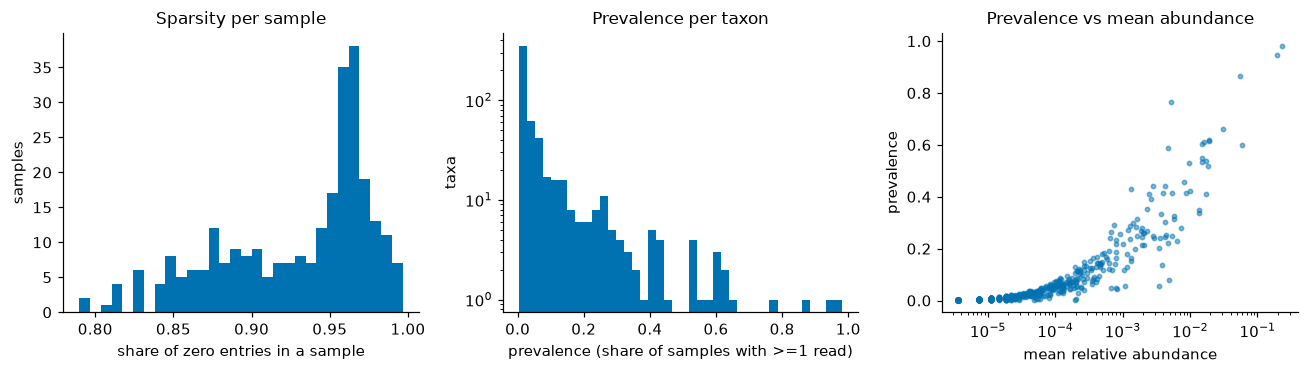

In [2]:
assigned = A.sum(axis=1)
print("nominal library size: %d reads for every sample (rarefied)" % READS)
print("assigned reads: median %d, min %d" % (assigned.median(), assigned.min()))
zero_per_sample = (A == 0).mean(axis=1)
prev = (A > 0).mean(axis=0); meanab = A.mean(axis=0) / READS
summary.update(sparsity_all=(A.values == 0).mean(), sparsity_filtered=(F.values == 0).mean(),
               n_taxa_all=A.shape[1], n_taxa_filtered=F.shape[1],
               median_prevalence=prev.median(), share_taxa_in_lt5pct=(prev < 0.05).mean())
print("zeros: %.3f (all labels), %.3f (filtered)" % (summary["sparsity_all"], summary["sparsity_filtered"]))
print("median prevalence %.3f; %.0f %% of labels occur in <5 %% of samples" % (prev.median(), 100*summary["share_taxa_in_lt5pct"]))

fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
ax[0].hist(zero_per_sample, bins=30, color=PALETTE[0]); ax[0].set(xlabel="share of zero entries in a sample", ylabel="samples", title="Sparsity per sample")
ax[1].hist(prev, bins=40, color=PALETTE[0]); ax[1].set(xlabel="prevalence (share of samples with >=1 read)", ylabel="taxa", yscale="log", title="Prevalence per taxon")
ax[2].scatter(meanab[meanab > 0], prev[meanab > 0], s=8, alpha=.5, color=PALETTE[0])
ax[2].set(xscale="log", xlabel="mean relative abundance", ylabel="prevalence", title="Prevalence vs mean abundance")
fig.tight_layout(); fig.savefig(FIGURES / "eda_sparsity.png"); plt.show()

## 2. Rank-abundance

Corynebacteriaceae;Corynebacterium              0.2301
Staphylococcaceae (unresolved below family)     0.1953
Porphyromonadaceae;Porphyromonas                0.0597
Clostridiaceae;Anaerococcus                     0.0553
Alicyclobacillaceae;Alicyclobacillus            0.0307
Clostridiaceae;Finegoldia                       0.0194
Prevotellaceae;Prevotella                       0.0193
Clostridiaceae (unresolved below family)        0.0185
Enterobacteriaceae (unresolved below family)    0.0172
Campylobacteraceae;Campylobacter                0.0170
median share of the single most abundant taxon within a sample: 0.42


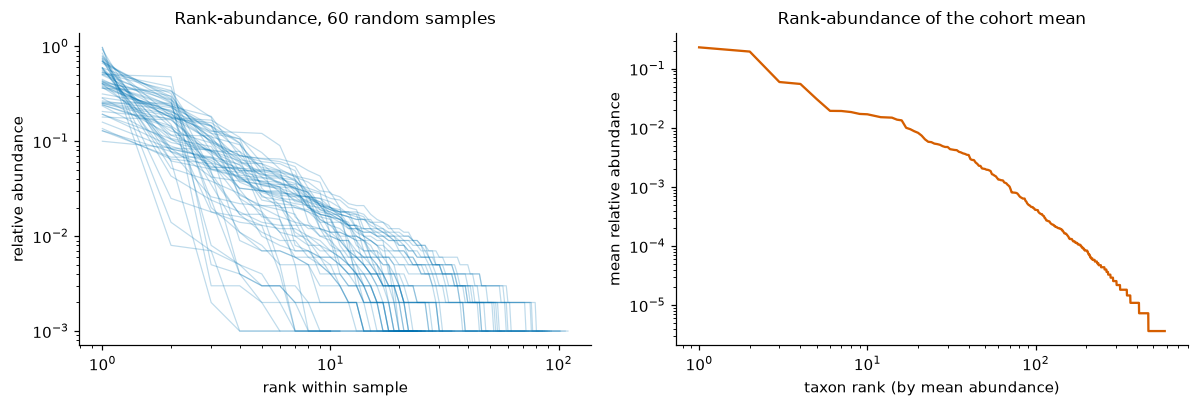

In [3]:
mean_rank = (A.mean(axis=0) / READS).sort_values(ascending=False)
top = mean_rank.head(10); print(top.round(4).to_string())
dominant_share = A.max(axis=1) / READS
summary.update(top1_taxon=mean_rank.index[0], top1_mean=mean_rank.iloc[0], top10_cum_mean=mean_rank.head(10).sum(),
               median_dominant_share=dominant_share.median())
print("median share of the single most abundant taxon within a sample: %.2f" % dominant_share.median())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for i in rng.choice(len(A), 60, replace=False):                     # thin lines: 60 random samples (Whittaker plot)
    v = np.sort(A.iloc[i].values)[::-1] / READS; v = v[v > 0]
    ax[0].plot(np.arange(1, len(v) + 1), v, color=PALETTE[0], alpha=.25, lw=.8)
ax[0].set(yscale="log", xscale="log", xlabel="rank within sample", ylabel="relative abundance", title="Rank-abundance, 60 random samples")
r = np.arange(1, len(mean_rank) + 1)
ax[1].plot(r, mean_rank.values, color=PALETTE[3]); ax[1].set(yscale="log", xscale="log", xlabel="taxon rank (by mean abundance)", ylabel="mean relative abundance", title="Rank-abundance of the cohort mean")
fig.tight_layout(); fig.savefig(FIGURES / "eda_rank_abundance.png"); plt.show()

## 3. Taylor's law and overdispersion
For each taxon: mean μ and variance σ² of its count over the 273 samples. Taylor's law: σ² = a·μᵇ, i.e. a straight line on log–log axes with slope b.
Reference for a **common-probability multinomial** (model M0): each count is ~Binomial(N, p), so σ² = N·p(1−p) = μ(1−μ/N): slope ≈ 1 and variance never above that curve.
Points far above it are **overdispersed**, which is what the Dirichlet-multinomial (M1) is meant to capture.

Taylor slope b = 1.84  (95% bootstrap CI 1.82-1.89); multinomial reference b = 1
overdispersion ratio var/(mu(1-mu/N)): median 21.9, IQR 7.1-93.5; share > 2: 1.00


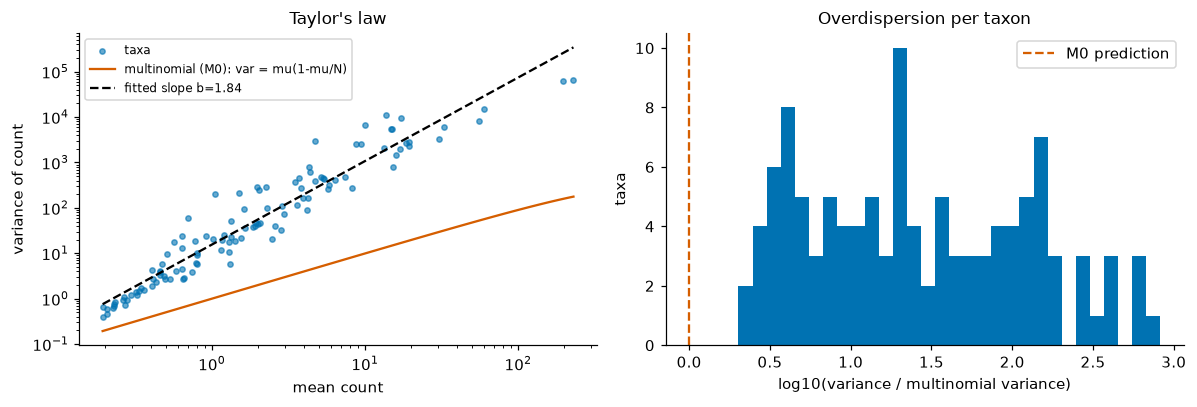

In [4]:
mu = F.mean(axis=0); v = F.var(axis=0, ddof=1)
ok = (mu > 0) & (v > 0)
binom_var = mu * (1 - mu / READS)
od = (v / binom_var)[ok]                     # overdispersion ratio per taxon; ~1 if M0 were right
def slope(mu_, v_):
    return np.polyfit(np.log10(mu_), np.log10(v_), 1)[0]
b = slope(mu[ok], v[ok])
boot = []
for _ in range(500):                         # non-parametric bootstrap over samples
    S = F.iloc[rng.integers(0, len(F), len(F))]; m_, v_ = S.mean(axis=0), S.var(axis=0, ddof=1); k = (m_ > 0) & (v_ > 0)
    boot.append(slope(m_[k], v_[k]))
lo, hi = np.percentile(boot, [2.5, 97.5])
summary.update(taylor_slope=b, taylor_lo=lo, taylor_hi=hi, overdisp_median=od.median(),
               overdisp_q25=od.quantile(.25), overdisp_q75=od.quantile(.75), share_overdisp_gt2=(od > 2).mean())
print("Taylor slope b = %.2f  (95%% bootstrap CI %.2f-%.2f); multinomial reference b = 1" % (b, lo, hi))
print("overdispersion ratio var/(mu(1-mu/N)): median %.1f, IQR %.1f-%.1f; share > 2: %.2f" % (od.median(), od.quantile(.25), od.quantile(.75), (od > 2).mean()))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].scatter(mu[ok], v[ok], s=12, alpha=.6, color=PALETTE[0], label="taxa")
g = np.logspace(np.log10(mu[ok].min()), np.log10(mu[ok].max()), 100)
ax[0].plot(g, g * (1 - g / READS), color=PALETTE[3], label="multinomial (M0): var = mu(1-mu/N)")
ax[0].plot(g, 10 ** (np.polyfit(np.log10(mu[ok]), np.log10(v[ok]), 1)[1]) * g ** b, "--", color="k", label="fitted slope b=%.2f" % b)
ax[0].set(xscale="log", yscale="log", xlabel="mean count", ylabel="variance of count", title="Taylor's law"); ax[0].legend(fontsize=8)
ax[1].hist(np.log10(od), bins=30, color=PALETTE[0]); ax[1].axvline(0, color=PALETTE[3], ls="--", label="M0 prediction")
ax[1].set(xlabel="log10(variance / multinomial variance)", ylabel="taxa", title="Overdispersion per taxon"); ax[1].legend()
fig.tight_layout(); fig.savefig(FIGURES / "eda_taylor.png"); plt.show()

## 4. Alpha diversity (richness, Shannon, Simpson)

In [5]:
alpha = pd.DataFrame({"richness": richness(A), "shannon": shannon(A), "simpson": simpson(A)}, index=A.index)
alpha = alpha.join(meta[["Gender", "Age", "Age_group", "Wash_Freq", "Wash_Group", "Navel", "Ethnicity", "assigned_reads"]])
print(alpha[["richness", "shannon", "simpson"]].describe().round(2).T.to_string())
for c in ["richness", "shannon", "simpson"]:
    summary[f"{c}_median"] = alpha[c].median(); summary[f"{c}_iqr"] = (alpha[c].quantile(.25), alpha[c].quantile(.75))
print("Spearman(richness, assigned reads) = %.2f  <- richness depends on how many reads were assigned" % stats.spearmanr(alpha["richness"], alpha["assigned_reads"])[0])

          count   mean    std   min    25%    50%    75%     max
richness  273.0  41.65  28.04  2.00  21.00  30.00  63.00  123.00
shannon   273.0   1.87   0.90  0.01   1.24   1.91   2.46    3.83
simpson   273.0   0.66   0.24  0.00   0.53   0.75   0.84    0.96
Spearman(richness, assigned reads) = -0.69  <- richness depends on how many reads were assigned


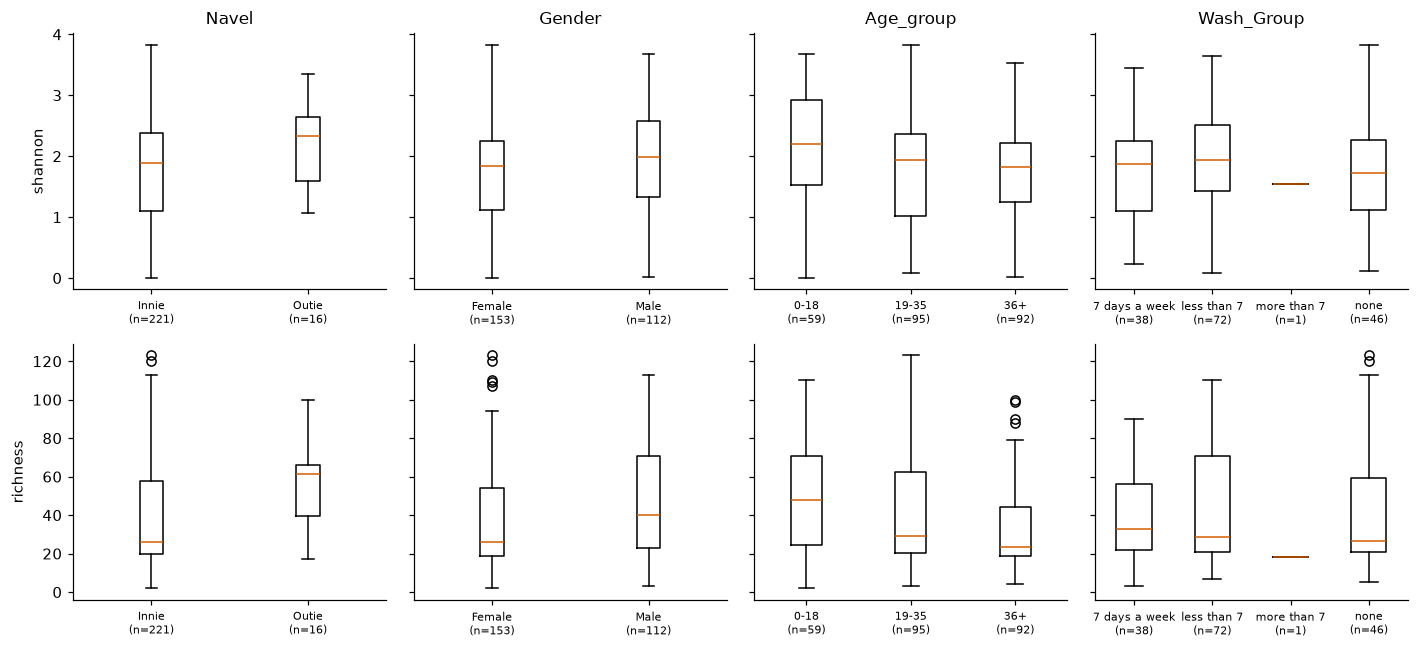

,metric,covariate,n,test,p,p_BH
0,shannon,Navel,237,Kruskal-Wallis,0.0523,0.0896
1,shannon,Gender,265,Kruskal-Wallis,0.0881,0.1322
2,shannon,Age_group,246,Kruskal-Wallis,0.0266,0.0533
3,shannon,Wash_Group,157,Kruskal-Wallis,0.7006,0.7918
4,richness,Navel,237,Kruskal-Wallis,0.0072,0.0215
5,richness,Gender,265,Kruskal-Wallis,0.0048,0.0193
6,richness,Age_group,246,Kruskal-Wallis,0.0021,0.0128
7,richness,Wash_Group,157,Kruskal-Wallis,0.6932,0.7918
8,shannon,Age,246,Spearman rho=-0.16,0.0129,0.0309
9,shannon,Wash_Freq,157,Spearman rho=0.01,0.9055,0.9055


In [6]:
cats = ["Navel", "Gender", "Age_group", "Wash_Group"]
fig, ax = plt.subplots(2, 4, figsize=(13, 6), sharey="row")
rows = []
for r_, met in enumerate(["shannon", "richness"]):
    for c_, cat in enumerate(cats):
        d = alpha[[met, cat]].dropna(); order = sorted(d[cat].unique(), key=str)
        data = [d.loc[d[cat] == o, met] for o in order]
        ax[r_, c_].boxplot(data, tick_labels=[f"{o}\n(n={len(x)})" for o, x in zip(order, data)], medianprops=dict(color=PALETTE[3]))
        ax[r_, c_].set_title(cat if r_ == 0 else ""); ax[r_, c_].tick_params(axis="x", labelsize=7)
        rows.append({"metric": met, "covariate": cat, "n": len(d), "test": "Kruskal-Wallis", "p": stats.kruskal(*data).pvalue})
    ax[r_, 0].set_ylabel(met)
for met in ["shannon", "richness"]:
    for cont in ["Age", "Wash_Freq"]:
        d = alpha[[met, cont]].dropna(); rho, p = stats.spearmanr(d[met], d[cont])
        rows.append({"metric": met, "covariate": cont, "n": len(d), "test": f"Spearman rho={rho:.2f}", "p": p})
fig.tight_layout(); fig.savefig(FIGURES / "eda_alpha_covariates.png"); plt.show()
alpha_tests = pd.DataFrame(rows); alpha_tests["p_BH"] = stats.false_discovery_control(alpha_tests["p"])
alpha_tests.round(4)

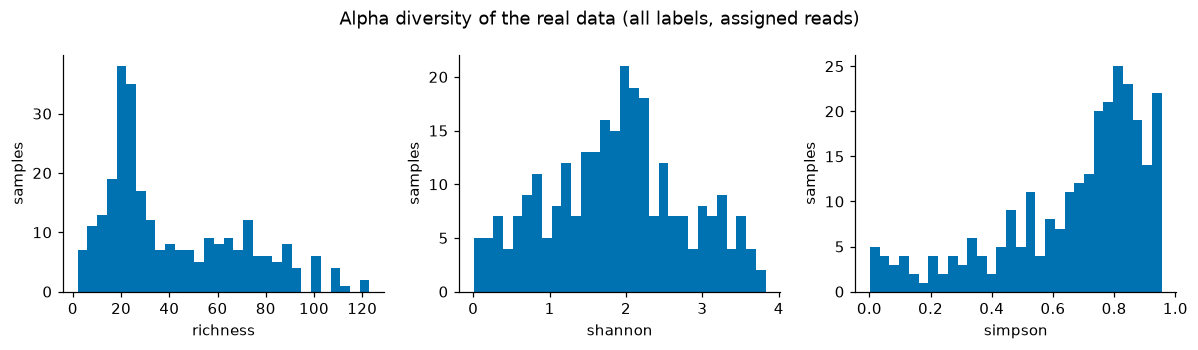

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.2))
for a_, c_ in zip(ax, ["richness", "shannon", "simpson"]):
    a_.hist(alpha[c_], bins=30, color=PALETTE[0]); a_.set(xlabel=c_, ylabel="samples")
fig.suptitle("Alpha diversity of the real data (all labels, assigned reads)"); fig.tight_layout()
fig.savefig(FIGURES / "eda_alpha_hist.png"); plt.show()

## 5. Beta diversity: Bray–Curtis and Aitchison, PCoA, PERMANOVA
* **Bray–Curtis** on counts: `1 − 2·Σmin(a,b)/(Σa+Σb)`; ignores shared zeros, bounded in [0,1].
* **Aitchison**: Euclidean distance between **CLR** vectors (`log(x+0.5)` centred per sample): scale-free, ratio-based; needs a pseudocount because of the zeros.
* PCoA of a non-Euclidean distance (Bray–Curtis) has some negative eigenvalues; the % explained uses the positive ones only.
Both distances use the 113 filtered categories (112 taxa + `Other`).

Bray-Curtis PCoA % explained (axes 1-3): [22.8 20.6 13.9]
Aitchison PCoA % explained (axes 1-3): [28.5  9.1  7.3]
Bray-Curtis between samples: median 0.79, 5-95% range 0.34-0.98


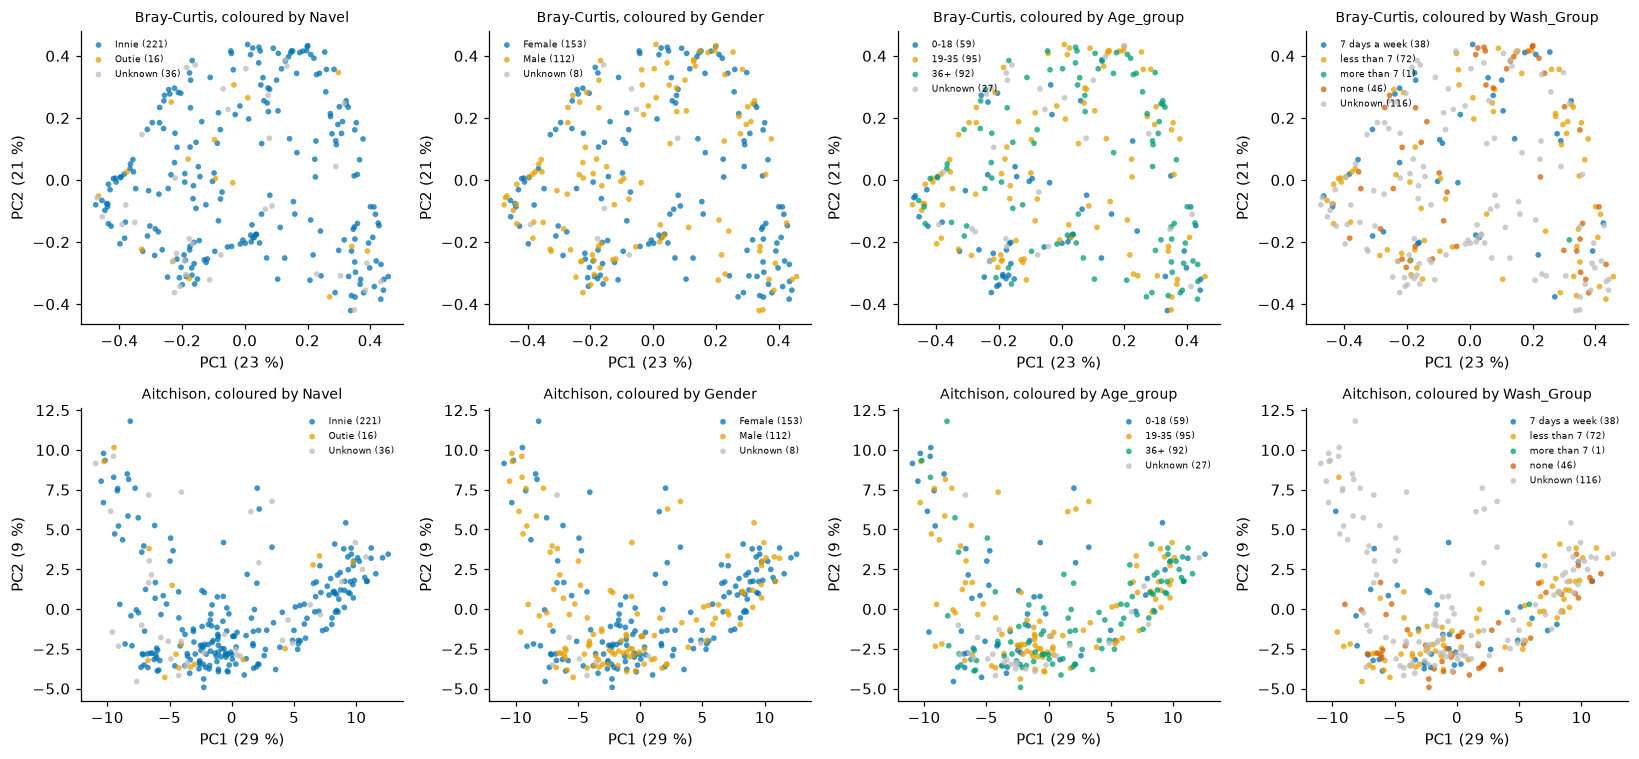

In [8]:
ids = F.index
dm = {"Bray-Curtis": bray_curtis(F.values, ids), "Aitchison": aitchison(F.values, ids, pseudo=0.5)}
pc = {k: pcoa(v, number_of_dimensions=5) for k, v in dm.items()}
for k in pc: print(k, "PCoA % explained (axes 1-3):", (100 * pc[k].proportion_explained.values[:3]).round(1))
summary.update(bc_pc1=pc["Bray-Curtis"].proportion_explained.values[0], bc_pc2=pc["Bray-Curtis"].proportion_explained.values[1],
               ait_pc1=pc["Aitchison"].proportion_explained.values[0], ait_pc2=pc["Aitchison"].proportion_explained.values[1])
bc_u = dm["Bray-Curtis"].condensed_form(); summary.update(bc_median=np.median(bc_u), bc_q05=np.quantile(bc_u, .05), bc_q95=np.quantile(bc_u, .95))
print("Bray-Curtis between samples: median %.2f, 5-95%% range %.2f-%.2f" % (summary["bc_median"], summary["bc_q05"], summary["bc_q95"]))

def scatter(ax, P, labels, title, cmap_cats=True):
    lab = labels.reindex(P.index).fillna("Unknown").astype(str); levels = sorted(lab.unique(), key=lambda s: (s == "Unknown", s))
    for j, lv in enumerate(levels):
        m = lab == lv
        ax.scatter(P.loc[m, "PC1"], P.loc[m, "PC2"], s=14, alpha=.75, color="#BBBBBB" if lv == "Unknown" else PALETTE[j % 7], label=f"{lv} ({m.sum()})", edgecolor="none")
    ax.set_title(title, fontsize=9); ax.legend(fontsize=6, frameon=False, loc="best")

fig, ax = plt.subplots(2, 4, figsize=(15, 7))
for r_, k in enumerate(dm):
    P = pc[k].samples; P.index = P.index.astype(str); ev = pc[k].proportion_explained.values
    for c_, cat in enumerate(["Navel", "Gender", "Age_group", "Wash_Group"]):
        scatter(ax[r_, c_], P, meta[cat], f"{k}, coloured by {cat}")
        ax[r_, c_].set(xlabel=f"PC1 ({100*ev[0]:.0f} %)", ylabel=f"PC2 ({100*ev[1]:.0f} %)")
fig.tight_layout(); fig.savefig(FIGURES / "eda_pcoa_covariates.png"); plt.show()

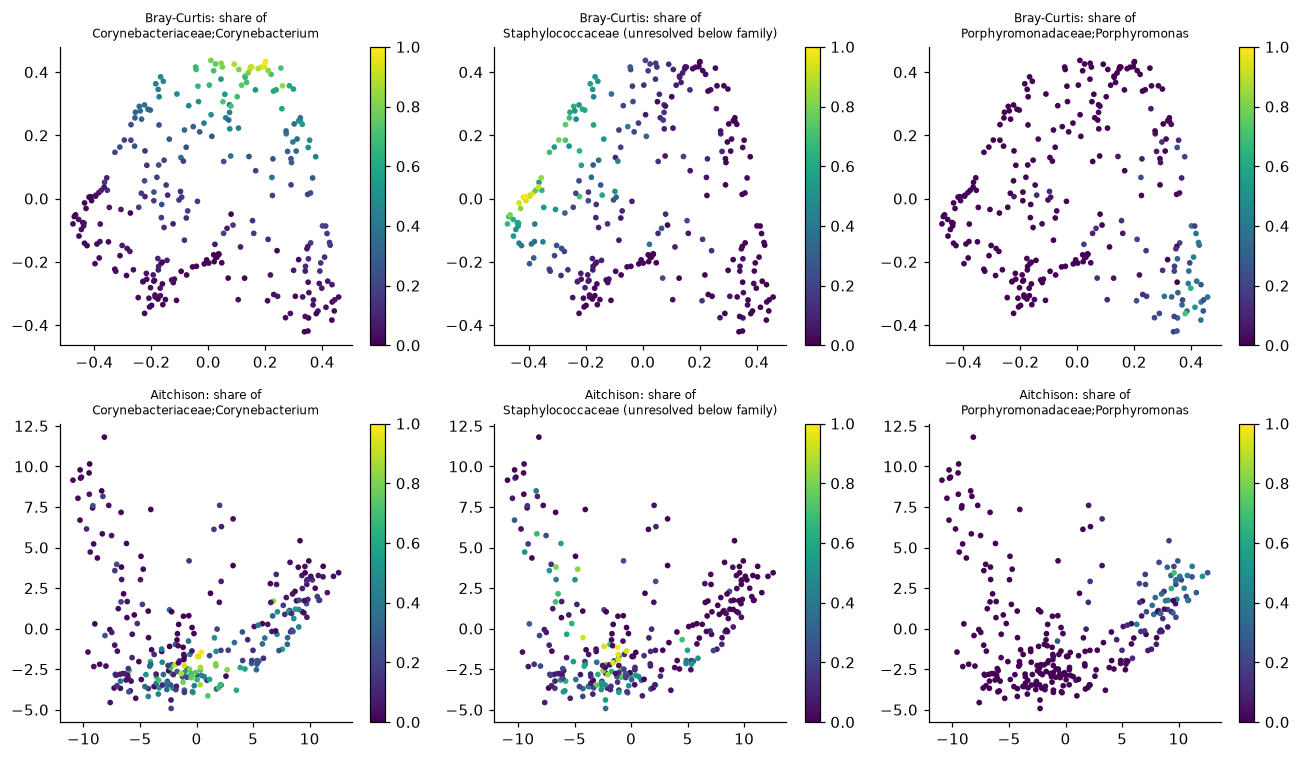

In [9]:
# the same ordination coloured by the abundance of the three most abundant taxa: what do the axes *mean*?
top3 = F.mean().sort_values(ascending=False).index[:3]
fig, ax = plt.subplots(2, 3, figsize=(12, 7))
for r_, k in enumerate(dm):
    P = pc[k].samples; P.index = P.index.astype(str)
    for c_, t in enumerate(top3):
        sc = ax[r_, c_].scatter(P["PC1"], P["PC2"], c=F[t].reindex(P.index) / READS, s=14, cmap="viridis", vmin=0, vmax=1, edgecolor="none")
        ax[r_, c_].set_title(f"{k}: share of\n{t}", fontsize=8); plt.colorbar(sc, ax=ax[r_, c_])
fig.tight_layout(); fig.savefig(FIGURES / "eda_pcoa_taxa.png"); plt.show()

In [10]:
# exploratory PERMANOVA of each covariate (complete cases for that covariate only); R2 = share of distance variance explained
rows = []
covs = {"Gender": "Gender", "Navel": "Navel", "Age_group": "Age_group", "Wash_Group": "Wash_Group", "Ethnicity": "Ethnicity", "In_NC": "In_NC"}
for k, D in dm.items():
    for name, col in covs.items():
        g = meta[[col]].dropna().astype(str); sub = D.filter(list(g.index))
        res = permanova(sub, g.loc[list(sub.ids)], column=col, permutations=999, seed=SEED)
        n, ng, Fst = int(res["sample size"]), int(res["number of groups"]), float(res["test statistic"])
        rows.append({"distance": k, "covariate": name, "n": n, "groups": ng, "pseudo-F": Fst,
                     "R2": Fst * (ng - 1) / (Fst * (ng - 1) + (n - ng)), "p": float(res["p-value"])})
perm = pd.DataFrame(rows); perm["p_BH"] = stats.false_discovery_control(perm["p"])   # BH over the 12 exploratory tests
perm.round(4)

,distance,covariate,n,groups,pseudo-F,R2,p,p_BH
0,Bray-Curtis,Gender,265,2,1.7658,0.0067,0.072,0.1080
1,Bray-Curtis,Navel,237,2,0.8584,0.0036,0.551,0.5510
2,Bray-Curtis,Age_group,246,3,3.4165,0.0274,0.001,0.0030
3,Bray-Curtis,Wash_Group,157,4,1.2139,0.0232,0.215,0.2580
4,Bray-Curtis,Ethnicity,239,3,1.0272,0.0086,0.433,0.4724
5,Bray-Curtis,In_NC,257,2,4.7277,0.0182,0.001,0.0030
6,Aitchison,Gender,265,2,2.4121,0.0091,0.014,0.0336
7,Aitchison,Navel,237,2,1.5567,0.0066,0.101,0.1347
8,Aitchison,Age_group,246,3,3.0838,0.0248,0.001,0.0030
9,Aitchison,Wash_Group,157,4,1.4137,0.0270,0.068,0.1080


## 6. Pseudocount sensitivity of the Aitchison distance
CLR needs a pseudocount for zeros. Compare Aitchison distances for pseudocounts 0.1, 0.5, 1, 2 (and Bray–Curtis) by the Spearman correlation of all pairwise distances.
If the correlation is high the choice hardly matters; if not, it must be fixed *before* the power study, because it affects the CLR-based tests there.

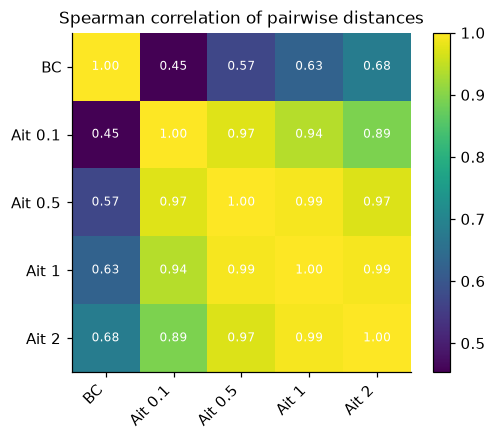

In [11]:
D = {"BC": bray_curtis(F.values, ids)} | {f"Ait {p}": aitchison(F.values, ids, pseudo=p) for p in [0.1, 0.5, 1, 2]}
M = pd.DataFrame({k: v.condensed_form() for k, v in D.items()}).corr(method="spearman")
summary["ait_pseudo_corr_min"] = M.loc[["Ait 0.1", "Ait 0.5", "Ait 1", "Ait 2"], ["Ait 0.1", "Ait 0.5", "Ait 1", "Ait 2"]].values.min()
fig, ax = plt.subplots(figsize=(4.8, 4))
im = ax.imshow(M.values, vmin=M.values.min(), vmax=1, cmap="viridis"); ax.set_xticks(range(len(M))); ax.set_yticks(range(len(M)))
ax.set_xticklabels(M.columns, rotation=45, ha="right"); ax.set_yticklabels(M.columns)
for i in range(len(M)):
    for j in range(len(M)): ax.text(j, i, f"{M.values[i,j]:.2f}", ha="center", va="center", color="w", fontsize=8)
ax.set_title("Spearman correlation of pairwise distances"); plt.colorbar(im); fig.tight_layout()
fig.savefig(FIGURES / "eda_pseudocount.png"); plt.show()

## 7. Note on compositional data (for the report and the oral)
* **Closure.** Each sample is divided by its total (here 1000 reads), so the data live on the **simplex** {x : xᵢ ≥ 0, Σxᵢ = 1}. Only ratios between parts carry information; the absolute amount of bacteria is unobserved.
* **Why ordinary statistics mislead.** If one taxon grows, all others shrink in relative terms. This induces negative correlations that are an artefact of closure (Aitchison 1986; Gloor et al. 2017), and Euclidean distance on proportions ignores the ratio structure.
* **Aitchison geometry.** Work with log-ratios. **CLR**: `clr(x)ᵢ = log xᵢ − mean(log x)`; rows sum to 0; Euclidean distance on CLR = Aitchison distance. **ALR**: `log(xᵢ/x_ref)` with a reference part (used by the logistic-normal model, M3). **ILR**: orthonormal coordinates (not used: coordinates are hard to interpret).
* **Zeros.** log 0 is undefined and the data are 93 % zeros. Options: pseudocount (simple, used here, sensitivity checked above), multiplicative replacement, or a model that handles zeros by construction (multinomial-type count models do). Zeros here are mostly *sampling* zeros (1000 reads cannot see rare taxa), not true absences.
* **Our choice:** count models (M0–M3) for generation, CLR + pseudocount 0.5 only for descriptive distances and the per-taxon tests in Phase 4.

## 8. Interactive PCoA (plotly, for exploration only)

In [12]:
import plotly.express as px, plotly.io as pio
pio.renderers.default = "notebook_connected"
P = pc["Aitchison"].samples.copy(); P.index = P.index.astype(str)
P = P.join(meta[["Age", "Gender", "Navel", "Wash_Freq"]]).assign(dominant=F.idxmax(axis=1).reindex(P.index), ID=P.index)
fig = px.scatter(P, x="PC1", y="PC2", color="dominant", hover_data=["ID", "Age", "Gender", "Navel", "Wash_Freq"], title="Aitchison PCoA (hover for metadata; colour = most abundant taxon)")
fig.update_traces(marker=dict(size=7)); fig.show()

## 9. Save key numbers (used by the report)

In [13]:
def flat(d):
    out = {}
    for k, v in d.items():
        if isinstance(v, tuple): out[k + "_q25"], out[k + "_q75"] = v
        else: out[k] = v
    return out
s = pd.Series(flat(summary)); s.to_csv(PROCESSED / "eda_summary.csv", header=["value"])
perm.to_csv(PROCESSED / "eda_permanova.csv", index=False); alpha_tests.to_csv(PROCESSED / "eda_alpha_tests.csv", index=False)
s.to_frame("value")

,value
sparsity_all,0.9288
sparsity_filtered,0.708613
n_taxa_all,585
n_taxa_filtered,113
median_prevalence,0.014652
share_taxa_in_lt5pct,0.697436
top1_taxon,Corynebacteriaceae;Corynebacterium
top1_mean,0.230125
top10_cum_mean,0.662462
median_dominant_share,0.419
